<a href="https://colab.research.google.com/github/catzmat/DATA201-labs/blob/main/Assignments/Catherine_Matenje_Week_8_HW_11_6_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Catherine Matenje

DATA 201

Week 8 Assignment

November 6, 2026

Dataset: ISLP Hitters

The data set represents the 1986 statistics of professional baseball players and their 1987 salaries.

Understanding the Problem and Exploring the Dataset

In [1]:
# Installing ISLP
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Importing Packages and loading the Data Set
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

hitters = load_data('Hitters')

In [3]:
# Exploring/inpecting the Data set and checking missing values

print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values()) # summing all missing values in data set, sorting from lowest to highest

# There are 322 rows and 20 columns
# Salary has 59 missing values

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [4]:
hitters['Salary'].max()*1000
hitters['Salary'].min()*1000

67500.0

In [5]:
# Dropping missing values
hitters = hitters.dropna(subset=['Salary']).copy()

*Defining my variables and splitting the data*

In [6]:
# Setting features/predictors (X) and target/response variable (Y)
X = hitters.drop(columns='Salary')
y = hitters['Salary']

# Finding numerical and categorical predictors
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

# Splitting into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Checking dimensions of training and testing sets
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


*Prepping data for processing*

In [7]:
# Create preprocessing steps for numerical and categorical predictors
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

# Define the preprocessing pipeline
baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))


,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


Part I: Experimenting with alpha

In [16]:
# Set up three alpha values: alpha 0.1, alpha = 10, alpha = 100
alpha_examples = [0.1, 10, 100 ]
rows = []

# Fitting Lasso models for each alpha value
for a in alpha_examples:
    estimator = Lasso(max_iter=30000)
    pipe = Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', estimator.set_params(alpha=a))
        ])
    pipe.fit(X_train, y_train)

    # Calculate training/test RMSE and count nonzero coefficients
    coefs = pipe.named_steps['model'].coef_

    # Save results
    rows.append({
          'alpha': a,
          'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))), # Training RMSE
          'Testing RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))), # Tetsing RMSE
          'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), # Count nonzero coefficients
      })
# Create comparison table
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))


,alpha,Training RMSE,Testing RMSE,Nonzero coefficients
0,0.1,289.38,356.83,19
1,10.0,303.10,381.84,9
2,100.0,341.39,395.12,5


1. As α increases, what happens to the number of retained predictors?


As alpha increases from 0.1 to 100, the number of retained predictors decreases. For example, my output shows that at alpha = 0.1, the model retains all 19 predictors. When alpha increases to 10, 9 predictors are kept and at alpha = 100, only 5 predictors are kept.

This shows that as alpha increases, LASSO applies penalizes the coefficients more strictly, which pushes more of them toward zero or exactly zero resulting in less predictors being retained in the model.

2. Does a smaller number of predictors always lead to a lower test RMSE?  

No, having fewer predictors does not always lead to a lower test RMSE. Looking at my output, when alpha = 0.1, the model retains 19 predictors and has a test RMSE of 365.83. When alpha = 100, only 5 predictors remained and the RMSE *increased* to 395.12.

This shows that while LASSO reduced the number of predictors to increase accuracy, the model may not actually make accurate predictions on the testing data. Less predictors means the model has been increasingly restricted which can actually remove potetially useful predictors.


Part II: Visualization and Interpretation

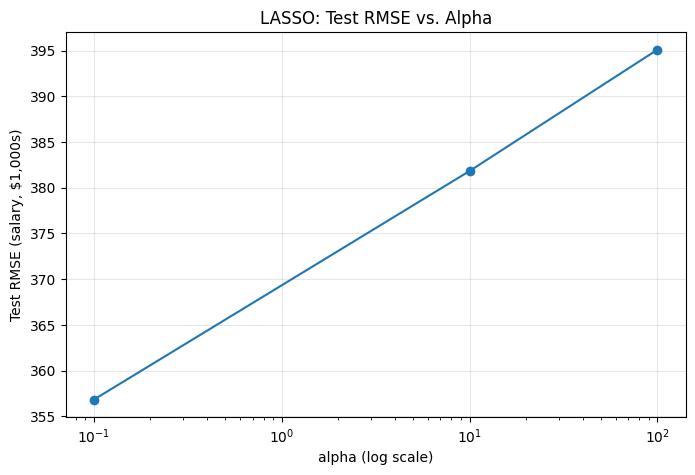

In [21]:
# Plot alpha vs. test RSME

fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogx(
    alpha_table['alpha'],
    alpha_table['Testing RMSE'],
    marker='o'
)

ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Test RMSE (salary, $1,000s)')
ax.set_title('LASSO: Test RMSE vs. Alpha')

ax.grid(alpha=0.3)

plt.show()



1. Which α produces the lowest test RMSE among the three values?

Among the three alpha values, alpha= 0.1 produces the lowest test RMSE at 356.83

2. Which α appears to cause the most underfitting? Explain using bias.

Alpha = 100 appears to cause the most underfitting in thsi model because it is putting the strongest restriction or penalty. When a = 100, LASSO pushes more coefficients toward zero and only leaves 5 predictors remaining.

This is considered high bias because the model is so restricted that it can miss importnat predictors and their relationship to the outcome, in this case salary. This means it can miss information and cause more predictor eorrors.


3. Why might a model with higher training RMSE produce lower test RMSE?

A model with higher traning RSME might produce a lower test RSME because regularization makes the model less flexible. Even though restricting a model can increase it's training erro, as in the output in Part I, it might help reduce the chances of overfitting by reducing noise the the model may have picked up in the training data. This can result inthe model performin better on new observations and having a lower RSME.

Part III: Model Interpretation

In [22]:
# Examine the coefficient values at alpha = 100

feature_names = pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Lasso': pipe.named_steps['model'].coef_
})

display(coef_table.round(2))



,Feature,Lasso
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


1. Identify two predictors that Lasso sets to zero at α = 100.

At alpha = 100, LASSO sets the coeffients of num_HmRun and num_Assists to zero

2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.

No, setting their coefficients to zero does not prove that these predictors have no relationship with salary. We know that LASSO sets coefficients to zero when applies penalties to reduce large coefficients which can push some to zero and remove them from the model.

When alpha = 100, the model applies the most restrictive penalty which only leaves behind 5 predictors as shown in the output above. This does not mean all the other predictors have no relationship with salary. Some of the predictors might still be useful and others might even be highly correlated with other predictors aka multicollinearity.


3. If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain your answer in terms of interpretability and predictive performance.

If two models have very similar test RSME, I would probably pick the one with fewer predictors because as we have learned in class so far, picking a simpler model is usually better. If both of them have similar test RMSE, it indicates that they are both performing similarly on the testing data and so selecting the model with fewer predictors can allow us to easily interpret the results.

At the same time, I think there is a slight trade off in that while fewer predictors mean a simpler model and easy interpretability, it doesn't mean it is more accurate at the prediction. It might be missing certain relationships still.

Part IV: Choosing the Right Regression Model

For each scenario, choose Ridge (L2), Lasso (L1), Ordinary Linear Regression, or Not Sure. Explain your choice in 2-3 sentences, considering the number of predictors, model complexity, interpretability, and potential overfitting.

1. Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.

I would choose LASSO regression because there are more predictors (200 medical measurements) than there are observations (80 patients), and the goal is to identify a smaller number of useful predictors. LASSO applies an L1 penalty which shrinks some coefficients to zero, which removes certain predictors and makes the model easier to interpret. The trade-off is that there is a risk of remove potentially useful predictors.I would first do cross-validation to choose an appropriate alpha so that the model does not become too restricted and eliminate too many predictors

2. Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.

I would choose Ridge regression because many of the 40 predictors are strongly correlated, and the company believes most of them contain useful information. Ridge applies an L2 penalty that shrinks the coefficients similar to LASSO but it also stabilizes them and does not typically remove predictors from the model. This would allow the company to retain the predictors which could be useful while also reducing the risk of overfitting and retaining noise in the model.

3. Scenario C: A researcher has 10,000 observations and only three predictors. The relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.

I would choose OLS regression because there are 10,000 observations and only three predictors, and the relationship appears approximately linear. Since the model has very few predictors compared to the number of observations, it might be less likely to overfit. OLS in this case would also be easy to interpret without needing regularization especially because there are only three predictors.

4. Scenario D: A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.

I am honestly not sure any of the models would fit for this Scenario. I don't believe we have enough information to make a decision. Initially, I though Ridge might be a good choice in order to retain as many predictors as possible rather than applying LASSO and risk losing useful predictors. However, we are told it is unclear which of the 25 predictors are useful or how strongly they are correlated. We are only told the goal is maintain accuracy. The only useful step in this case is to compare models using cross validation to test which one does well on training data.